# KeyLeak: Acoustic Side-Channel Attack on a Laptop Keyboard, and Defences Against It

**Question:** can a microphone tell which key was pressed from the sound alone, and can cheap defences stop it?

This notebook is the complete story of the project in one place: the data I collected, how I checked and cleaned it, how the features were built, which models I used and why, how I evaluated them, and every result, including the ones that are not flattering.

**Contents**
1. Idea and threat model
2. Data collection
3. Data audit and cleaning
4. Features
5. Models and why I chose them
6. Evaluation design
7. Experiment 1: how well does the attack work?
8. Experiment 2: do the defences work?
9. Experiment 3: the adaptive attacker
10. Experiment 4: ablations (clip window, high-pass filter)
11. Experiment 5: a neural network and data augmentation (development sessions)
12. The final held-out test (session 16, used once)
13. How much does this help a password attacker?
14. Real-time style test (replay of the live demo)
15. Limitations and honest conclusions
16. How to re-run with more sessions


## 1. Idea and threat model

Each key on a keyboard produces a slightly different click, because of where the key sits on the plate, how the case resonates and which finger presses it. A microphone in the same room (for example the laptop's own microphone during a call) can record those clicks. An **attacker** who has audio of the target's typing, plus some labelled examples of that keyboard, trains a classifier that maps a click to a letter.

**Scope of this study**
- 26 classes (the keys A to Z), one laptop (its built-in keyboard and built-in microphone), one typist.
- **Attack:** MFCC features with an SVM and a Random Forest, and a small neural network on log-mel spectrograms.
- **Defence:** two cheap, physical ones: dampening (cloth) and controlled background noise.
- **Adaptive attacker:** an attacker who knows about the defence and retrains on defended recordings.

**Ethics.** All audio is my own typing on my own keyboard. No passwords, no other people's typing and no private data were recorded.

In [1]:
import os, sys, re, time, warnings, importlib.util, pickle
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
from scipy.signal import butter, sosfiltfilt
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", message="The number of unique classes")

# ---- locate the project (works from the project root or from final_notebook/)
cwd = Path.cwd()
ROOT = Path(os.environ.get("KEYLEAK_ROOT") or (cwd.parent if cwd.name == "final_notebook" else cwd))
OUT = Path(os.environ.get("KEYLEAK_OUT") or (ROOT / "final_notebook"))
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RAW = ROOT / "dataset" / "raw"
sys.path.insert(0, str(ROOT / "src"))
import extract_features as ef          # the same feature code used by the command-line scripts

# ---- experiment configuration (edit this cell when you add sessions)
CLEAN_DEV = ["session_06", "session_07", "session_11", "session_14", "session_15"]   # clean sessions used for training and development
FINAL_TEST = "session_16"                                      # clean session kept out of every choice, evaluated at the end
CLEAN = CLEAN_DEV                                              # (name kept for the sections below)
CLEAN_ALL = CLEAN_DEV + [FINAL_TEST]
DEFENDED = {                                                   # session -> (condition, setup)
    "session_08": ("dampened", "cloth under the stand"),
    "session_09": ("dampened", "cloth over the keys"),
    "session_13": ("dampened", "cloth over the keys"),
    "session_19": ("dampened", "cloth over the keys"),
    "session_20": ("dampened", "cloth over the keys"),
    "session_10": ("noisy", "white noise (phone)"),
    "session_12": ("noisy", "white noise (phone)"),
    "session_17": ("noisy", "white noise (phone)"),
    "session_18": ("noisy", "white noise (phone, a bit louder)"),
}
DEFENCES = {"White noise": ["session_10", "session_12", "session_17", "session_18"],
            "Cloth over the keys": ["session_09", "session_13", "session_19", "session_20"]}
TRAIN_BASE = CLEAN_DEV                                         # clean training sessions for the defence tests
BASELINE_TEST = FINAL_TEST                                     # clean session the attacker has never heard
PRE, POST, HP = 0.02, 0.08, 0.0                                # clip: 20 ms before to 80 ms after key-down; no high-pass
SEED = 42
# optional cache so a long notebook can be re-run quickly (set KEYLEAK_CACHE to a folder; unset = no cache)
_cd = os.environ.get("KEYLEAK_CACHE")
CACHE = Path(_cd) if _cd else None
if CACHE: CACHE.mkdir(parents=True, exist_ok=True)
def cached(name, fn):
    if CACHE is None:
        return fn()
    p = CACHE / f"{name}.pkl"
    if p.exists():
        return pickle.load(open(p, "rb"))
    v = fn()
    pickle.dump(v, open(p, "wb"))
    return v
FEAT = ([f"mfcc{i}_mean" for i in range(1, ef.N_MFCC)] + [f"mfcc{i}_std" for i in range(1, ef.N_MFCC)])

# ---- plot style: thin marks, quiet grid, colour-blind-safe palette (Okabe-Ito)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})
C_CLEAN, C_UNDER, C_OVER, C_NOISE, C_GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#767676"

meta = pd.read_csv(ROOT / "dataset" / "metadata_master.csv")
print("project root :", ROOT)
print("metadata rows:", len(meta), "| sessions:", meta.session.nunique())

project root : /sessions/rcw-01to2qvxwerckt8j3rjg3dak/mnt/AcousticKeyword
metadata rows: 569 | sessions: 20


## 2. Data collection

**Recording protocol** (the same for every session that is used in the experiments)
- Built-in laptop microphone, 44.1 kHz mono, laptop on a stand on a wooden table, lid at about 110 degrees, normal typing posture.
- Windows microphone "enhancements" (noise suppression) switched **off** and input volume 100 (see the cleaning section for why).
- **Burst recordings:** for each letter a 5 second recording in which I press that one key five times, about one second apart. The 26 letters are visited in a freshly randomised order every session (the random seed is saved).
- **Key logger:** while recording, a small logger stores the exact time of every press and release of the target key (relative to the first audio sample). Other keys are only counted, never stored. This gives each click a trustworthy label and time.
- A 3 second room-noise recording is saved at the start of every session.
- A take can be redone. Rejected takes are **kept** in a `rejected/` folder and logged in the metadata, never deleted.

**Conditions**
- `clean`: no defence, quiet room.
- `dampened`: cloth under the laptop stand, or a thin cloth laid over the keys.
- `noisy`: steady white noise played from a phone about 50 cm from the laptop.

Sessions 01 to 05 are earlier pilot recordings made before the key logger existed; they are kept as raw data but are not used in the experiments (explained below).

In [2]:
rows = []
used = set(CLEAN_ALL) | set(DEFENDED)
for s in sorted(meta.session.unique()):
    m = meta[meta.session == s]
    acc = m[m.quality_flag != "REJECTED"]
    rows.append(dict(session=s, condition=m.condition.iloc[0],
                     recording=", ".join(sorted(m.recording_type.dropna().astype(str).unique())),
                     accepted=len(acc), rejected=int((m.quality_flag == "REJECTED").sum()),
                     clipped=int((acc.quality_flag == "POSSIBLE_CLIPPING").sum()),
                     near_silent=int((acc.quality_flag == "LOW_PEAK").sum()),
                     key_log=(RAW / s / "events").is_dir(),
                     used_in_experiments=s in used))
sessions_table = pd.DataFrame(rows)
display(sessions_table)
n_used = sessions_table[sessions_table.used_in_experiments].accepted.sum()
print(f"\nRecordings used in the experiments: {int(n_used)} burst files = about {int(n_used) * 5} labelled key presses")

,session,condition,recording,accepted,rejected,clipped,near_silent,key_log,used_in_experiments
0,session_01,noisy_pilot,single,78,0,0,36,False,False
1,session_02,noisy_pilot,burst,1,0,0,0,False,False
2,session_03,noisy_pilot,burst,26,0,0,0,False,False
3,session_04,noisy_pilot,burst,1,0,0,0,False,False
4,session_05,clean,burst,26,3,0,0,False,False
5,session_06,clean,burst,26,1,1,0,True,True
6,session_07,clean,burst,26,6,1,0,True,True
7,session_08,dampened,burst,26,3,1,0,True,True
8,session_09,dampened,burst,26,9,0,0,True,True
9,session_10,noisy,burst,26,1,0,0,True,True



Recordings used in the experiments: 390 burst files = about 1950 labelled key presses


## 3. Data audit and cleaning

Before any model was trained I audited the data. Problems found, and what I did about each, in the order they were found:

| Problem found | Evidence | What I did |
|---|---|---|
| **Near-silent clips** in the first pilot session (36 of 78 single-press clips) | peak amplitude below 0.01 | kept as raw data, labelled `noisy_pilot`, **excluded** from the experiments |
| **Inconsistent metadata:** old 7-column file, plus a stale duplicate row for one recording | audit scripts | built a new 14-column `metadata_master.csv`; the original file was left untouched |
| **Windows noise suppression** was silently removing the background and distorting the sound | room noise RMS about 0.0007 with enhancements on versus about 0.01 with them off | enhancements **off**, input volume 100, 48 kHz Windows format, identical for all sessions |
| **Typed letters leaking** into the terminal prompt during a take | stray characters in the prompts | the script now flushes the keyboard buffer after each take |
| **Press counts typed by hand** disagreed with a detector on 9 of 26 files in the first clean session | manual check | replaced hand counts with a **key logger**; that older session has no key log, so it is **not used** in the experiments |
| **Audio and key log misaligned** by about 0.6 s | test run: click minus key-down about -586 ms | rewrote the recorder (microphone stream opened first, key times measured from the first audio sample); see the evidence below |
| **Clipping and wrong press counts** during real sessions | peak near 1.0, logger counts of 4 or 6 | clipped takes flagged (not removed); takes with the wrong count were redone and the rejected take kept |

The next cells show the evidence for the three problems that can be checked from the saved data: alignment, room noise and press counts.

,session,condition,presses,median_ms,p5_ms,p95_ms,reliable_check
0,session_06,clean,130,21.3,19.7,24.0,yes
1,session_07,clean,130,20.7,18.5,25.8,yes
2,session_11,clean,130,18.5,-6.1,21.1,yes
3,session_14,clean,130,-4.6,-26.1,18.7,yes
4,session_15,clean,130,-9.5,-33.5,17.9,yes
5,session_16,clean,130,-9.2,-29.8,17.7,yes
6,session_08,dampened,130,18.1,-4.4,21.3,no: faint clicks
7,session_09,dampened,130,12.4,-37.4,26.0,no: faint clicks
8,session_13,dampened,130,-0.4,-19.2,24.9,no: faint clicks
9,session_19,dampened,131,-5.5,-27.9,25.2,no: faint clicks


The check finds the loudest point near each logged key-down. On the clean sessions the click is the loudest thing,
so the result is trustworthy. On the cloth and white-noise sessions the click is faint or masked, so the loudest
point is sometimes something else and the spread (p5) gets wide. The recorder code is identical for all sessions,
but alignment on the defended sessions is therefore NOT independently verified by this method.


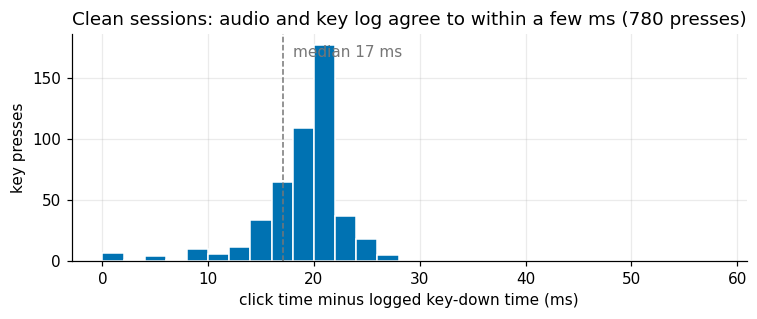

In [3]:
def click_offsets(session):
    # click time (loudest point of the 300 Hz high-passed envelope) minus the logged key-down time, in ms
    offs = []
    for key in ef.KEYS:
        wav = RAW / session / f"{key}_burst.wav"
        if not wav.exists():
            continue
        a, sr = sf.read(wav, dtype="float32")
        a = a[:, 0] if a.ndim == 2 else a
        y = ef.highpass(a, sr, 300)
        h = 44
        n = len(y) // h * h
        env = np.sqrt((y[:n].reshape(-1, h) ** 2).mean(axis=1))
        t = np.arange(len(env)) * h / sr
        for d in ef.read_down_times(RAW / session / "events" / f"{key}_events.csv", key):
            i = np.where((t >= d - 0.1) & (t <= d + 0.15))[0]
            if len(i):
                offs.append((t[i[np.argmax(env[i])]] - d) * 1000)
    return np.array(offs)

all_sessions = CLEAN_ALL + list(DEFENDED)
off = cached('off', lambda: {s: click_offsets(s) for s in all_sessions})
rows = [dict(session=s, condition=meta.loc[meta.session == s, "condition"].iloc[0], presses=len(o),
             median_ms=round(float(np.median(o)), 1), p5_ms=round(float(np.percentile(o, 5)), 1),
             p95_ms=round(float(np.percentile(o, 95)), 1),
             reliable_check="yes" if s in CLEAN_ALL else "no: faint clicks")
        for s, o in off.items()]
display(pd.DataFrame(rows))
print("The check finds the loudest point near each logged key-down. On the clean sessions the click is the loudest thing,")
print("so the result is trustworthy. On the cloth and white-noise sessions the click is faint or masked, so the loudest")
print("point is sometimes something else and the spread (p5) gets wide. The recorder code is identical for all sessions,")
print("but alignment on the defended sessions is therefore NOT independently verified by this method.")

fig, ax = plt.subplots(figsize=(7, 3))
allo = np.concatenate([off[s] for s in CLEAN_ALL])
ax.hist(allo, bins=np.arange(0, 60, 2), color=C_CLEAN, edgecolor="white")
ax.axvline(np.median(allo), color=C_GREY, ls="--", lw=1)
ax.text(np.median(allo) + 1, ax.get_ylim()[1] * 0.9, f"median {np.median(allo):.0f} ms", color=C_GREY)
ax.set_xlabel("click time minus logged key-down time (ms)")
ax.set_ylabel("key presses")
ax.set_title(f"Clean sessions: audio and key log agree to within a few ms ({len(allo)} presses)")
fig.tight_layout(); fig.savefig(FIG / "alignment.png"); plt.show()

In [4]:
# room noise by frequency band: a white-noise session shows up as extra energy between 200 Hz and 8 kHz,
# a low rumble shows up only below 200 Hz
def noise_bands(session):
    p = RAW / session / "ambient" / "noise_floor.wav"
    if not p.exists():
        return None
    x, sr = sf.read(p, dtype="float32")
    x = x[:, 0] if x.ndim == 2 else x
    P = np.abs(np.fft.rfft(x)) ** 2 / len(x) ** 2
    f = np.fft.rfftfreq(len(x), 1 / sr)
    band = lambda lo, hi: float(np.sqrt(2 * P[(f >= lo) & (f < hi)].sum()))
    return dict(session=session, condition=meta.loc[meta.session == session, "condition"].iloc[0],
                total_rms=round(float(np.sqrt((x ** 2).mean())), 5), below_200Hz=round(band(0, 200), 5),
                f200_2k=round(band(200, 2000), 5), f2k_8k=round(band(2000, 8000), 5))

nb = [r for r in (noise_bands(s) for s in all_sessions) if r]
nb_df = pd.DataFrame(nb)
display(nb_df)
print()

# press counts: every accepted take should hold exactly 5 logged presses
acc = meta[(meta.quality_flag != "REJECTED") & (meta.session.isin(all_sessions))]
print("accepted takes in the experiment sessions:", len(acc))
print("logged press counts:", dict(Counter(acc.actual_presses.astype(int))))
print("rejected takes kept in rejected/ folders :", int((meta[meta.session.isin(all_sessions)].quality_flag == "REJECTED").sum()))

,session,condition,total_rms,below_200Hz,f200_2k,f2k_8k
0,session_06,clean,0.01173,0.01166,0.00120,0.00048
1,session_07,clean,0.01192,0.01182,0.00155,0.00052
2,session_11,clean,0.01837,0.01836,0.00171,0.00049
3,session_14,clean,0.01340,0.01327,0.00181,0.00054
4,session_15,clean,0.01117,0.01112,0.00145,0.00048
5,session_16,clean,0.01353,0.01340,0.00160,0.00050
6,session_08,dampened,0.01143,0.01137,0.00162,0.00060
7,session_09,dampened,0.01424,0.01405,0.00234,0.00061
8,session_13,dampened,0.01184,0.01171,0.00187,0.00051
9,session_19,dampened,0.01522,0.01513,0.00172,0.00053



accepted takes in the experiment sessions: 390
logged press counts: {5: 388, 6: 2}
rejected takes kept in rejected/ folders : 44


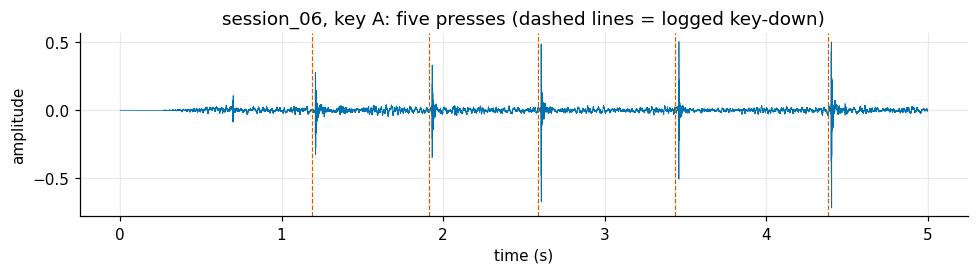

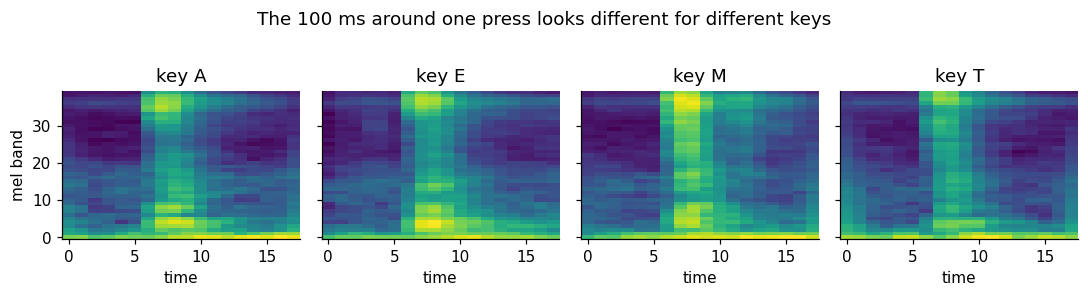

In [5]:
# what the raw signal looks like: one 5 s burst with the logged key-downs, and a mel spectrogram of four different keys
s0 = CLEAN[0]
a, sr = sf.read(RAW / s0 / "A_burst.wav", dtype="float32")
a = a[:, 0] if a.ndim == 2 else a
downs = ef.read_down_times(RAW / s0 / "events" / "A_events.csv", "A")

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(np.arange(len(a)) / sr, a, color=C_CLEAN, lw=0.5)
for d in downs:
    ax.axvline(d, color=C_NOISE, lw=0.8, ls="--")
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
ax.set_title(f"{s0}, key A: five presses (dashed lines = logged key-down)")
fig.tight_layout(); fig.savefig(FIG / "waveform.png"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6), sharey=True)
for ax, key in zip(axes, ["A", "E", "M", "T"]):
    aa, sr = sf.read(RAW / s0 / f"{key}_burst.wav", dtype="float32")
    aa = aa[:, 0] if aa.ndim == 2 else aa
    d = ef.read_down_times(RAW / s0 / "events" / f"{key}_events.csv", key)[0]
    clip = aa[int(round((d - PRE) * sr)):int(round((d + POST) * sr))]
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=clip, sr=sr, n_fft=ef.N_FFT, hop_length=ef.HOP, n_mels=ef.N_MELS))
    ax.imshow(S, origin="lower", aspect="auto", cmap="viridis")
    ax.set_title(f"key {key}"); ax.set_xlabel("time"); ax.grid(False)
axes[0].set_ylabel("mel band")
fig.suptitle("The 100 ms around one press looks different for different keys", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "spectrograms.png", bbox_inches="tight"); plt.show()

## 4. Features

For every logged key-down, one clip is cut from 20 ms before to 80 ms after the key-down (100 ms in total). That window holds the press click, where the key bottoms out. Using the logged time means the labels are exact.

Each clip is then turned into a small fixed-length description:
1. Scale the clip so its loudest sample is 1, so that how hard I pressed does not leak in as a clue.
2. Compute **MFCCs** (Mel-frequency cepstral coefficients): a compact summary of the spectrum on a perceptual (mel) frequency scale. 20 coefficients per short frame, using a 1024-sample FFT and a hop of 256, with 40 mel bands.
3. Drop coefficient 0, which only measures loudness.
4. For each of the remaining 19 coefficients keep the **mean and the standard deviation over time**.

That gives **38 numbers per key press**.

A note on honesty: because I cut clips with the *logged* press times, segmentation is not part of what is being tested. A real attacker would not have a key log. The live demo (section 14) therefore also tests a version where the clicks are found from the audio alone.

In [6]:
def build(sessions, pre=PRE, post=POST, hp=HP):
    # one row per logged key press: session, condition, key, press_index and the 38 features
    out = []
    for s in sessions:
        cond = meta.loc[meta.session == s, "condition"].iloc[0]
        for key in ef.KEYS:
            wav = RAW / s / f"{key}_burst.wav"
            evf = RAW / s / "events" / f"{key}_events.csv"
            audio, sr = sf.read(wav, dtype="float32")
            audio = audio[:, 0] if audio.ndim == 2 else audio
            if hp > 0:
                audio = ef.highpass(audio, sr, hp)
            for idx, t in enumerate(ef.read_down_times(evf, key), start=1):
                a0, a1 = int(round((t - pre) * sr)), int(round((t + post) * sr))
                if a0 < 0 or a1 > len(audio):
                    continue            # a press too close to the end of the recording (rare, counted below)
                feats, _, _ = ef.clip_features(audio[a0:a1], sr)
                out.append(dict(session=s, condition=cond, key=key, press_index=idx, t_down=float(t),
                                **{n: float(v) for n, v in zip(FEAT, feats)}))
    return pd.DataFrame(out)

t0 = time.time()
ALL = cached('ALL', lambda: build(all_sessions))
print(f"{len(ALL)} key presses x {len(FEAT)} features   ({time.time() - t0:.0f} s)")
display(ALL.groupby(["session", "condition"]).size().rename("presses").to_frame().T)

# consistency check against the features file made by the command-line script (if it exists)
csvs = sorted((ROOT / "results").glob("features_*.csv"), key=lambda p: p.stat().st_mtime)
for p in reversed(csvs):
    ref = pd.read_csv(p)
    if set(all_sessions) <= set(ref.session):
        ref = ref[ref.session.isin(all_sessions)].set_index(["session", "key", "press_index"])
        mine = ALL.set_index(["session", "key", "press_index"])
        common = mine.index.intersection(ref.index)
        diff = float(np.abs(mine.loc[common, FEAT].values - ref.loc[common, FEAT].values).max())
        print(f"matches {p.name}: {len(common)} presses compared, largest difference {diff:.2e}")
        break

1951 key presses x 38 features   (0 s)


session,session_06,session_07,session_08,session_09,session_10,session_11,session_12,session_13,session_14,session_15,session_16,session_17,session_18,session_19,session_20
condition,clean,clean,dampened,dampened,noisy,clean,noisy,dampened,clean,clean,clean,noisy,noisy,dampened,dampened
presses,130,130,129,130,130,130,131,130,130,130,130,130,130,131,130


matches features_s06_s07_s08_s09_s10_s11_s12_s13_s14_s15_s16_s17_s18_s19_s20_pre20_post80.csv: 1951 presses compared, largest difference 7.11e-15


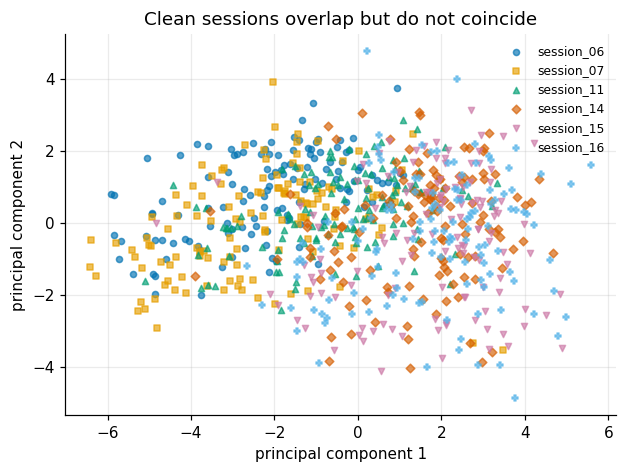

In [7]:
# do the sessions differ from each other? PCA of the 38 features of the clean sessions
pool = ALL[ALL.session.isin(CLEAN_ALL)]
Z = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(pool[FEAT].values))
fig, ax = plt.subplots(figsize=(5.8, 4.4))
for s, mk, col in zip(CLEAN_ALL, ["o", "s", "^", "D", "v", "P"], [C_CLEAN, C_UNDER, C_OVER, C_NOISE, "#CC79A7", "#56B4E9"]):
    m = (pool.session == s).values
    ax.scatter(Z[m, 0], Z[m, 1], marker=mk, s=16, alpha=0.65, color=col, label=s)
ax.set_xlabel("principal component 1"); ax.set_ylabel("principal component 2")
ax.set_title("Clean sessions overlap but do not coincide")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "pca_sessions.png"); plt.show()

## 5. Models and why I chose them

I used two classical models, deliberately simple, because the dataset is small (130 labelled clicks per session), and later added one small neural network for comparison.

- **Support Vector Machine with an RBF kernel (SVM).** Works well on small datasets with a modest number of features, finds non-linear boundaries between classes, and is a standard choice for MFCC-style audio features. The regularisation strength `C` is chosen by cross-validation on the training data only. Its `decision_function` gives a score per key, which I use to rank guesses (top-3 and top-5).
- **Random Forest (300 trees).** A completely different model family (many decision trees voting). It needs little tuning, copes with unscaled and noisy features, and gives class probabilities. If both models behave similarly, the result is less likely to be an accident of one algorithm.

- **Small neural network (MLP, log-mel input).** Added in Experiment 5 to follow what the literature does (spectrogram input, learned model). Input: the log-mel spectrogram of the 100 ms clip (40 mel bands), reduced with PCA to 100 numbers, then one hidden layer of 128 units. It is trained with five different random seeds because a neural net's result changes a little with its starting point.

I did **not** use a large deep model such as CoAtNet: with 130 clicks per session and a laptop without a graphics card there is not enough data or compute, and the goal is to measure the effect of the defences, not to win an accuracy contest. Features are standardised (zero mean, unit variance) using **training data only**.

## 6. Evaluation design

The most important design decision in the project:

> **The attacker is always tested on a recording session it has never heard.**

If clips from the same recording end up on both sides of a train/test split, the model can recognise the *session* (the room, the way I typed that day) instead of the *key*, and the accuracy looks far better than it really is. Experiment 1 shows how large that effect is.

Rules I followed:
- Train and test sessions are always different sessions.
- Standardisation and the SVM `C` value are fitted on training data only. Test sessions are never used for any choice.
- Metrics are **top-1** (is the first guess right?), **top-3** and **top-5** accuracy. Guessing at random gives 3.8%, 11.5% and 19.2%.
- Each test session has about 130 presses, so a top-1 accuracy has about **±7 points** of statistical uncertainty (95% interval, shown as error bars). Differences smaller than that should not be trusted.
- Conditions are labelled honestly (`clean`, `dampened`, `noisy`) and every defended session is only compared with clean sessions recorded with the same setup otherwise.
- **One clean session (16) is kept out of every choice.** Development (sessions 06, 07, 11, 14, 15) is used to compare models, windows and augmentation; the configuration is then fixed, and session 16 is evaluated at the end.

In [8]:
CHANCE1, CHANCE3, CHANCE5 = 100 / 26, 300 / 26, 500 / 26

def topk(scores, classes, y, k):
    order = np.argsort(-scores, axis=1)[:, :k]
    return float(np.mean([yy in classes[r] for yy, r in zip(y, order)])) * 100

def ci95(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n) * 100

def fit(train):
    sc = StandardScaler().fit(train[FEAT].values)
    X, y = sc.transform(train[FEAT].values), train.key.values
    cv = StratifiedKFold(int(min(5, Counter(y).most_common()[-1][1])), shuffle=True, random_state=SEED)
    svm = GridSearchCV(SVC(kernel="rbf", gamma="scale", decision_function_shape="ovr"),
                       {"C": [1, 10, 100]}, cv=cv).fit(X, y).best_estimator_
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X, y)
    return sc, svm, rf

def evaluate(models, test):
    sc, svm, rf = models
    X, y = sc.transform(test[FEAT].values), test.key.values
    out = {"n": len(y), "y": y}
    for name, m, scores in (("SVM", svm, svm.decision_function(X)), ("RF", rf, rf.predict_proba(X))):
        pred = m.predict(X)
        acc = float(np.mean(pred == y))
        out[name] = dict(top1=acc * 100, ci=ci95(acc, len(y)), top3=topk(scores, m.classes_, y, 3),
                         top5=topk(scores, m.classes_, y, 5), pred=pred)
    return out

def run(train_sessions, test_session, df=None):
    df = ALL if df is None else df
    assert test_session not in train_sessions, "test session must differ from the training sessions"
    return evaluate(fit(df[df.session.isin(train_sessions)]), df[df.session == test_session])

def short(ss):
    return "+".join(s.replace("session_", "") for s in ss)

print("helpers ready")

helpers ready


## 7. Experiment 1: how well does the attack work?

Five clean development sessions (06, 07, 11, 14, 15) let me test the attacker on a session it has not heard in every possible way:
- **4 training sessions, 1 test session** (leave one session out): 5 combinations.
- **1 training session, 1 test session**: 20 combinations. Comparing 1 versus 4 training sessions shows how much more data helps.

Session 16 is not used here; it is reserved for the final test.

4 training sessions -> 1 unseen session (leave one session out)


,train,test,n_train,SVM_top1,SVM_top3,SVM_top5,RF_top1,RF_top3,RF_top5
0,07+11+14+15,06,520,30.0,62.3,77.7,34.6,66.2,77.7
1,06+11+14+15,07,520,25.4,54.6,70.0,24.6,60.0,71.5
2,06+07+14+15,11,520,37.7,63.1,76.2,40.8,66.2,76.9
3,06+07+11+15,14,520,42.3,70.8,86.9,37.7,70.0,82.3
4,06+07+11+14,15,520,43.8,73.8,83.8,35.4,61.5,77.7


1 training session -> 1 unseen session


,train,test,n_train,SVM_top1,SVM_top5,RF_top1,RF_top5
0,06,07,130,28.5,68.5,30.0,62.3
1,06,11,130,17.7,50.8,23.1,60.8
2,06,14,130,13.1,40.0,16.2,51.5
3,06,15,130,13.1,43.1,14.6,49.2
4,07,06,130,30.8,64.6,30.0,63.8
5,07,11,130,13.8,50.0,17.7,46.9
6,07,14,130,11.5,38.5,6.9,32.3
7,07,15,130,8.5,41.5,10.0,36.2
8,11,06,130,20.8,53.8,20.0,57.7
9,11,07,130,16.2,45.4,14.6,52.3


chance: top-1 3.8%   top-3 11.5%   top-5 19.2%


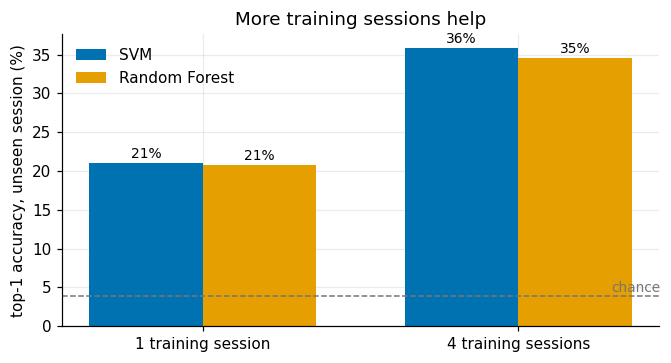

In [9]:
def _exp1():
    loso_rows, y_all, p_all = [], [], []
    for held in CLEAN:
        tr = [s for s in CLEAN if s != held]
        r = run(tr, held)
        loso_rows.append(dict(train=short(tr), test=short([held]), n_train=int(ALL.session.isin(tr).sum()),
                              SVM_top1=r["SVM"]["top1"], SVM_top3=r["SVM"]["top3"], SVM_top5=r["SVM"]["top5"],
                              RF_top1=r["RF"]["top1"], RF_top3=r["RF"]["top3"], RF_top5=r["RF"]["top5"]))
        y_all += list(r["y"]); p_all += list(r["SVM"]["pred"])
    loso = pd.DataFrame(loso_rows)

    pair_rows = []
    for a in CLEAN:
        for b in CLEAN:
            if a != b:
                r = run([a], b)
                pair_rows.append(dict(train=short([a]), test=short([b]), n_train=int((ALL.session == a).sum()),
                                      SVM_top1=r["SVM"]["top1"], SVM_top5=r["SVM"]["top5"],
                                      RF_top1=r["RF"]["top1"], RF_top5=r["RF"]["top5"]))
    pairs = pd.DataFrame(pair_rows)
    return loso, pairs, y_all, p_all
loso, pairs, y_all, p_all = cached('exp1', _exp1)

print("4 training sessions -> 1 unseen session (leave one session out)")
display(loso.round(1))
print("1 training session -> 1 unseen session")
display(pairs.round(1))
print(f"chance: top-1 {CHANCE1:.1f}%   top-3 {CHANCE3:.1f}%   top-5 {CHANCE5:.1f}%")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
vals = {"1 training session": (pairs.SVM_top1.mean(), pairs.RF_top1.mean()),
        "4 training sessions": (loso.SVM_top1.mean(), loso.RF_top1.mean())}
x = np.arange(2); w = 0.36
for j, (name, col) in enumerate((("SVM", C_CLEAN), ("Random Forest", C_UNDER))):
    b = ax.bar(x + (j - 0.5) * w, [v[j] for v in vals.values()], w, color=col, label=name)
    for rect in b:
        ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.6, f"{rect.get_height():.0f}%", ha="center", fontsize=9)
ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1); ax.text(1.45, CHANCE1 + 0.6, "chance", color=C_GREY, ha="right", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(vals.keys()); ax.set_ylabel("top-1 accuracy, unseen session (%)")
ax.set_title("More training sessions help"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "more_data.png"); plt.show()

**Reading the result.** Trained on **one** session the attacker averages **21% top-1 and 54% top-5** on a session it has never heard (it varies a lot: 8% to 43% depending on which two sessions are paired). Trained on **four** sessions it averages **36% top-1 and 79% top-5** (range 25% to 44%). Guessing blindly would give 3.8% and 19%. So the leak is real, and more training sessions is the biggest single lever: going from 1 to 4 sessions lifts top-1 by about 15 points. The SVM and the Random Forest behave almost the same, which suggests the result is not an accident of one algorithm. Session 07 is the hardest to predict (25%) and session 15 the easiest (44%): how I type and the room differ from day to day.

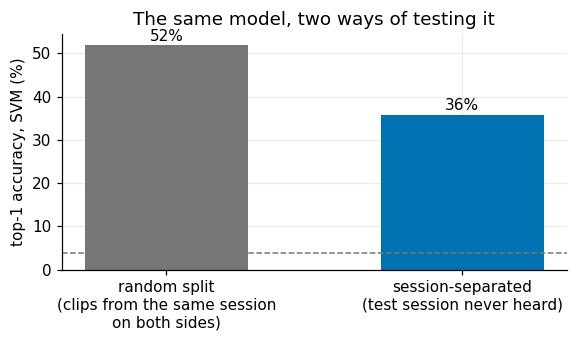

random split: 51.8%   session-separated: 35.8%


In [10]:
# Why session-separated testing matters: the same model, tested the easy way and the honest way
pool = ALL[ALL.session.isin(CLEAN_DEV)]
leaky = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
                        pool[FEAT].values, pool.key.values,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).mean() * 100
honest = loso.SVM_top1.mean()

fig, ax = plt.subplots(figsize=(5.4, 3.2))
b = ax.bar(["random split\n(clips from the same session\non both sides)", "session-separated\n(test session never heard)"],
           [leaky, honest], color=[C_GREY, C_CLEAN], width=0.55)
for rect in b:
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 1, f"{rect.get_height():.0f}%", ha="center")
ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1)
ax.set_ylabel("top-1 accuracy, SVM (%)"); ax.set_title("The same model, two ways of testing it")
fig.tight_layout(); fig.savefig(FIG / "leaky_vs_honest.png"); plt.show()
print(f"random split: {leaky:.1f}%   session-separated: {honest:.1f}%")

**Reading the result.** The same SVM scores **52% with a random split** (clips from the same recording on both sides) but **36% when tested on a session it has never heard**. About 16 points of the random-split score come from the model recognising the *session* instead of the *key*. Every number elsewhere in this notebook uses the honest, session-separated way.

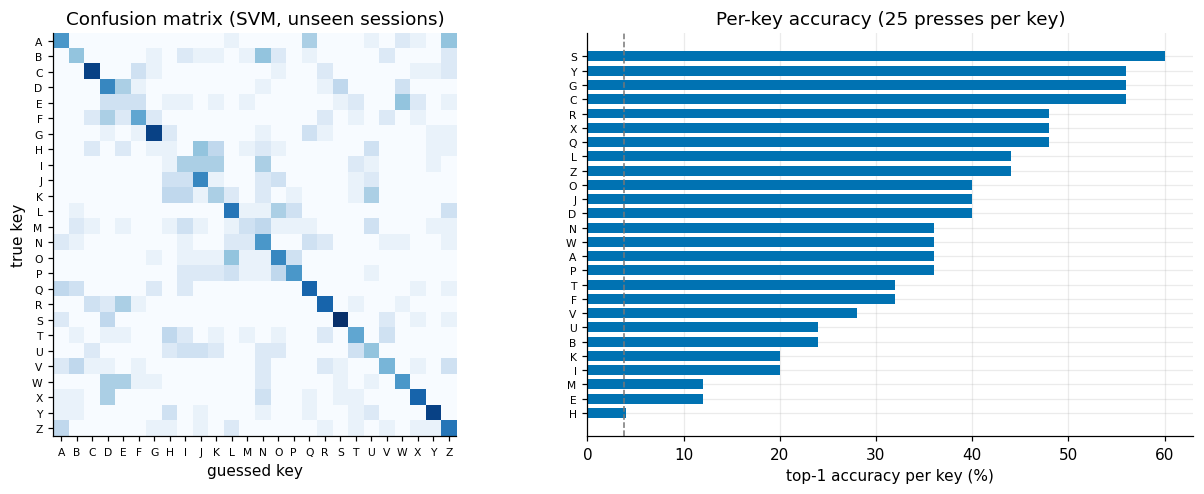

most common mistakes (true -> guessed, count): A->Z:6, B->N:6, E->W:6, H->J:6, O->L:6, A->Q:5, D->E:5, F->D:5
best keys : S 60%, Y 56%, G 56%, C 56%, R 48%
worst keys: H 4%, E 12%, M 12%, I 20%, K 20%


In [11]:
# which keys are easy or hard? pooled over the five leave-one-session-out runs (25 presses per key)
y_all, p_all = np.array(y_all), np.array(p_all)
keys = ef.KEYS
cm = np.zeros((26, 26), dtype=int)
for t, p in zip(y_all, p_all):
    cm[keys.index(t), keys.index(p)] += 1
per_key = np.diag(cm) / cm.sum(axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(cm, cmap="Blues"); axes[0].grid(False)
axes[0].set_xticks(range(26)); axes[0].set_xticklabels(keys, fontsize=7)
axes[0].set_yticks(range(26)); axes[0].set_yticklabels(keys, fontsize=7)
axes[0].set_xlabel("guessed key"); axes[0].set_ylabel("true key")
axes[0].set_title("Confusion matrix (SVM, unseen sessions)")
order = np.argsort(per_key)
axes[1].barh([keys[i] for i in order], per_key[order], color=C_CLEAN, height=0.7)
axes[1].axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
axes[1].set_xlabel("top-1 accuracy per key (%)"); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title("Per-key accuracy (25 presses per key)")
fig.tight_layout(); fig.savefig(FIG / "confusion.png"); plt.show()

conf = Counter((t, p) for t, p in zip(y_all, p_all) if t != p)
print("most common mistakes (true -> guessed, count):", ", ".join(f"{t}->{p}:{c}" for (t, p), c in conf.most_common(8)))
print("best keys :", ", ".join(f"{keys[i]} {per_key[i]:.0f}%" for i in order[::-1][:5]))
print("worst keys:", ", ".join(f"{keys[i]} {per_key[i]:.0f}%" for i in order[:5]))

**Reading the result.** Some keys are much easier than others: S (60%), Y, G and C (56% each) are the best, while H (4%), E and M (12% each) are the worst. Many of the common mistakes are between keys that sit close together on the keyboard (for example H and J, B and N, F and D, E and W), which makes sense because nearby keys sound alike. With only 25 presses per key, each per-key number is rough (about ±19 points), so treat the ranking as a hint, not a fact.

## 8. Experiment 2: do the defences work?

The attacker is trained on **clean** typing only (the five development sessions) and tested on sessions it has never heard: a clean one (session 16, the baseline) and each defended one. If a defence works, accuracy falls well below the clean baseline. (Session 16 is only ever scored by models trained on the development sessions, and no choice is made from it.)

,setup,session,n,SVM_top1,SVM_pm,SVM_top3,SVM_top5,RF_top1,RF_top5
0,clean (baseline),16,130,46.9,8.6,73.1,84.6,49.2,83.8
1,cloth under stand,08,129,34.1,8.2,57.4,72.1,34.1,72.1
2,cloth over keys (a),09,130,17.7,6.6,36.9,45.4,18.5,49.2
3,cloth over keys (b),13,130,25.4,7.5,54.6,69.2,24.6,63.8
4,cloth over keys (c),19,131,36.6,8.3,51.9,67.2,26.0,65.6
5,cloth over keys (d),20,130,27.7,7.7,50.0,62.3,18.5,58.5
6,white noise (a),10,130,4.6,3.6,12.3,21.5,16.2,38.5
7,white noise (b),12,131,3.8,3.3,11.5,19.1,5.3,24.4
8,white noise (c),17,130,5.4,3.9,11.5,19.2,10.8,32.3
9,white noise (d),18,130,4.6,3.6,11.5,18.5,5.4,29.2


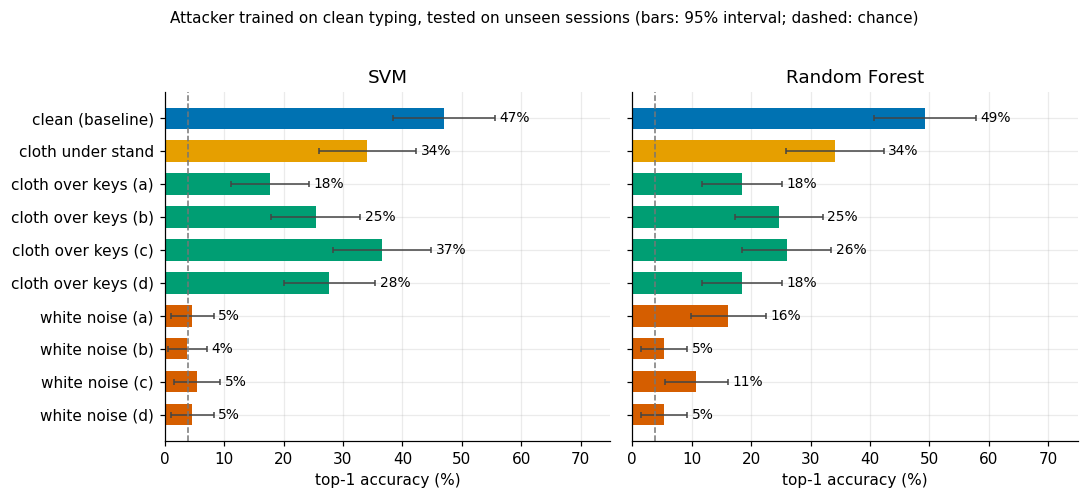

In [12]:
setups = [("clean (baseline)", BASELINE_TEST, C_CLEAN), ("cloth under stand", "session_08", C_UNDER)]
setups += [(f"cloth over keys ({c})", s, C_OVER) for c, s in zip("abcd", DEFENCES["Cloth over the keys"])]
setups += [(f"white noise ({c})", s, C_NOISE) for c, s in zip("abcd", DEFENCES["White noise"])]
_m2 = fit(ALL[ALL.session.isin(TRAIN_BASE)])
res2 = {lab: evaluate(_m2, ALL[ALL.session == s]) for lab, s, _ in setups}

tbl = pd.DataFrame([dict(setup=lab, session=s.replace("session_", ""), n=res2[lab]["n"],
                         SVM_top1=res2[lab]["SVM"]["top1"], SVM_pm=res2[lab]["SVM"]["ci"],
                         SVM_top3=res2[lab]["SVM"]["top3"], SVM_top5=res2[lab]["SVM"]["top5"],
                         RF_top1=res2[lab]["RF"]["top1"], RF_top5=res2[lab]["RF"]["top5"]) for lab, s, _ in setups])
display(tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, model, title in zip(axes, ("SVM", "RF"), ("SVM", "Random Forest")):
    labs = [lab for lab, _, _ in setups][::-1]
    cols = [c for _, _, c in setups][::-1]
    v = [res2[l][model]["top1"] for l in labs]
    e = [res2[l][model]["ci"] for l in labs]
    ax.barh(labs, v, xerr=e, color=cols, height=0.65, error_kw=dict(lw=1, capsize=2, ecolor="#444"))
    for i, val in enumerate(v):
        ax.text(val + e[i] + 0.8, i, f"{val:.0f}%", va="center", fontsize=9)
    ax.axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
    ax.set_xlabel("top-1 accuracy (%)"); ax.set_title(title); ax.set_xlim(0, 75)
fig.suptitle("Attacker trained on clean typing, tested on unseen sessions (bars: 95% interval; dashed: chance)", y=1.02, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "defences.png", bbox_inches="tight"); plt.show()

**Reading the result.** On the clean reference session (16) the attacker gets **47% top-1 and 85% top-5** (SVM). Against each defence:
- **Cloth under the stand:** 34% top-1. A modest drop; with ±8 points of uncertainty it is only borderline.
- **Cloth over the keys (four sessions):** 18%, 25%, 37% and 28%, average **27%**. A clear drop of roughly 20 points, but not a consistent one: session 19 only fell to 37%.
- **White noise (four sessions):** **4% to 5%**, which is chance (3.8%); top-5 is also at chance (about 19%). The Random Forest keeps a little above chance on some noisy sessions (5% to 16%).

So noise is the strong defence against an attacker who trained on clean typing, cloth over the keys helps but does not stop the attack.

## 9. Experiment 3: the adaptive attacker

A defence that only works against an attacker who does not know about it is weak. Here the attacker **knows the defence** and trains on defended recordings. For each defence I recorded four sessions, so the attacker can train on some defended sessions and be tested on another (never the same session).

Three attackers per defence:
1. **Clean-trained** (as before): never saw defended audio.
2. **Adaptive, one defended session:** trained on *one* other defended session, tested on a different one (every combination).
3. **Adaptive plus clean:** trained on the clean sessions *and* one defended session.
4. **Strongest adaptive attacker:** trained on *all the other* defended sessions of that defence (three sessions), with and without the clean sessions.

For fairness there are also **references**: no defence at all, with one clean training session (the same amount of data as attacker 2) and with all five clean sessions.

In [13]:
def mean_row(label, runs):
    n = sum(r["n"] for r in runs)
    out = dict(attacker=label)
    for m in ("SVM", "RF"):
        t1 = float(np.average([r[m]["top1"] for r in runs], weights=[r["n"] for r in runs]))
        out[f"{m}_top1"] = t1
        out[f"{m}_pm"] = ci95(t1 / 100, n)
        out[f"{m}_top5"] = float(np.average([r[m]["top5"] for r in runs], weights=[r["n"] for r in runs]))
    return out

def adaptive_runs(tag, ds):
    others = lambda d: [x for x in ds if x != d]
    G = {"clean": lambda: [run(TRAIN_BASE, d) for d in ds],
         "one": lambda: [run([d2], d) for d in ds for d2 in others(d)],
         "one_clean": lambda: [run(TRAIN_BASE + [d2], d) for d in ds for d2 in others(d)],
         "all": lambda: [run(others(d), d) for d in ds],
         "all_clean": lambda: [run(TRAIN_BASE + others(d), d) for d in ds]}
    return {k: cached(f"ad_{tag}_{k}", f) for k, f in G.items()}

ref_runs = [run([a], BASELINE_TEST) for a in TRAIN_BASE]
ref_all = [run(TRAIN_BASE, BASELINE_TEST)]
print("reference attackers ready")

reference attackers ready


In [14]:
AD = {}
AD["White noise"] = adaptive_runs("noise", DEFENCES["White noise"])
print("white noise: done")

white noise: done


In [15]:
AD["Cloth over the keys"] = adaptive_runs("cloth", DEFENCES["Cloth over the keys"])
print("cloth: done")

cloth: done


White noise


,attacker,SVM_top1,SVM_pm,SVM_top5,RF_top1,RF_pm,RF_top5
0,"no defence, 1 clean training session (reference)",24.5,3.3,58.9,24.6,3.3,59.5
1,"no defence, 5 clean training sessions (reference)",46.9,8.6,84.6,49.2,8.6,83.8
2,clean-trained attacker,4.6,1.8,19.6,9.4,2.5,31.1
3,adaptive: 1 defended session,7.7,1.3,25.7,6.8,1.3,31.3
4,adaptive: 1 defended + clean sessions,10.8,1.5,35.6,11.6,1.6,38.6
5,adaptive: 3 defended sessions,14.4,3.0,44.3,15.9,3.1,49.1
6,adaptive: 3 defended + clean sessions,16.5,3.2,46.6,14.0,3.0,48.8


Cloth over the keys


,attacker,SVM_top1,SVM_pm,SVM_top5,RF_top1,RF_pm,RF_top5
0,"no defence, 1 clean training session (reference)",24.5,3.3,58.9,24.6,3.3,59.5
1,"no defence, 5 clean training sessions (reference)",46.9,8.6,84.6,49.2,8.6,83.8
2,clean-trained attacker,26.9,3.8,61.0,21.9,3.6,59.3
3,adaptive: 1 defended session,17.7,1.9,48.9,16.6,1.8,47.9
4,adaptive: 1 defended + clean sessions,28.6,2.2,63.9,27.9,2.2,61.3
5,adaptive: 3 defended sessions,28.2,3.9,63.0,25.7,3.8,61.4
6,adaptive: 3 defended + clean sessions,30.7,4.0,70.4,30.1,3.9,66.6


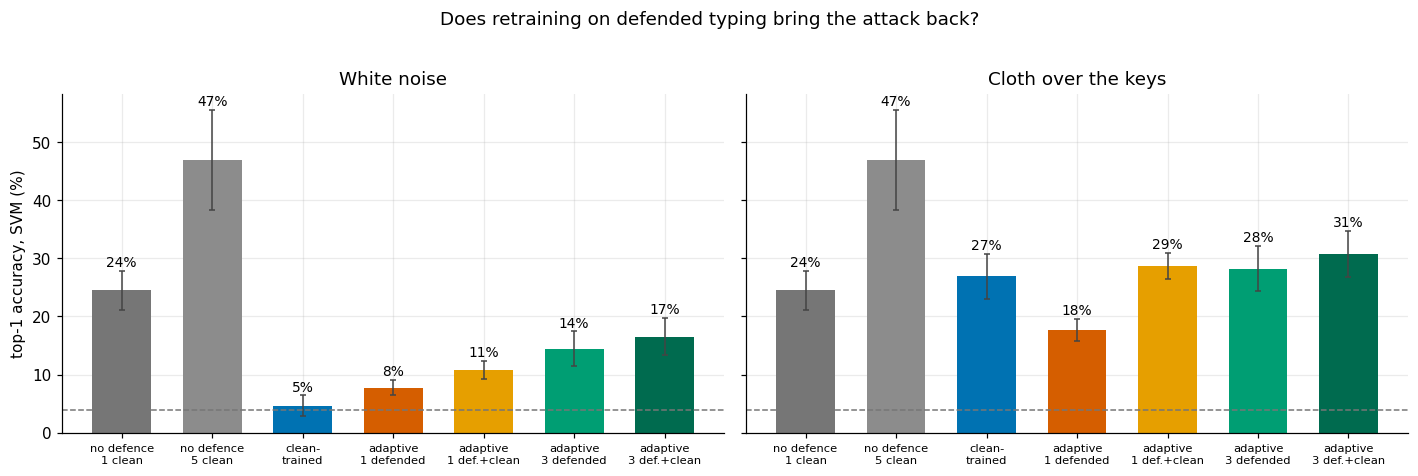

In [16]:
adaptive_rows = []
for name in DEFENCES:
    R = AD[name]
    block = [mean_row("no defence, 1 clean training session (reference)", ref_runs),
             mean_row("no defence, 5 clean training sessions (reference)", ref_all),
             mean_row("clean-trained attacker", R["clean"]),
             mean_row("adaptive: 1 defended session", R["one"]),
             mean_row("adaptive: 1 defended + clean sessions", R["one_clean"]),
             mean_row("adaptive: 3 defended sessions", R["all"]),
             mean_row("adaptive: 3 defended + clean sessions", R["all_clean"])]
    for b in block:
        b["defence"] = name
    adaptive_rows += block
adaptive = pd.DataFrame(adaptive_rows)
for name in DEFENCES:
    print(name)
    display(adaptive[adaptive.defence == name].drop(columns="defence").round(1).reset_index(drop=True))

fig, axes = plt.subplots(1, len(DEFENCES), figsize=(13, 4.2), sharey=True)
cols = [C_GREY, "#8c8c8c", C_CLEAN, C_NOISE, "#E69F00", C_OVER, "#006b4f"]
for ax, name in zip(np.atleast_1d(axes), DEFENCES):
    d = adaptive[adaptive.defence == name].reset_index(drop=True)
    labs = ["no defence\n1 clean", "no defence\n5 clean", "clean-\ntrained", "adaptive\n1 defended", "adaptive\n1 def.+clean", "adaptive\n3 defended", "adaptive\n3 def.+clean"]
    b = ax.bar(labs, d.SVM_top1, yerr=d.SVM_pm, color=cols, width=0.65, error_kw=dict(lw=1, capsize=2, ecolor="#444"))
    for rect, v, e in zip(b, d.SVM_top1, d.SVM_pm):
        ax.text(rect.get_x() + rect.get_width() / 2, v + e + 0.8, f"{v:.0f}%", ha="center", fontsize=9)
    ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1)
    ax.set_title(name); ax.tick_params(axis="x", labelsize=7.5)
np.atleast_1d(axes)[0].set_ylabel("top-1 accuracy, SVM (%)")
fig.suptitle("Does retraining on defended typing bring the attack back?", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "adaptive.png", bbox_inches="tight"); plt.show()

**Reading the result.** *White noise is no longer the unbeatable defence once the attacker has enough noisy training data.* The clean-trained attacker is at chance (5%). Training on one noisy session lifts it to 8% (11% with the clean sessions added), and on **three** noisy sessions to **14%** (16.5% with clean sessions added; top-5 47% against 19% chance). That is clearly above chance but still far below the 47% an attacker gets on undefended typing. So noise costs the attacker most of its accuracy, and an adaptive attacker with more data wins some back.

*Cloth over the keys:* the clean-trained attacker gets 27%; adapting does not remove the drop. One defended session alone is worse (18%, too little data), and with clean sessions plus defended ones it reaches 28% to 31% (top-5 up to 70%). So the cloth cuts accuracy from about 47% to about 30% and retraining does not bring it back to the undefended level.

Caution: the attackers that use more sessions also have more training data, which is part of why they improve; the intervals (±2 to ±4 points) only cover the test presses, not session-to-session variation. An earlier version of this notebook, with only two noisy sessions, suggested noise stayed near chance even against the adaptive attacker; with more sessions that conclusion has to be softened.

## 10. Experiment 4: ablations (clip window and high-pass filter)

Two cheap design choices that might matter: how much audio around the click goes into the features, and whether removing the low-frequency rumble (a 300 Hz high-pass filter) helps. Each variant is scored the same way: leave one development session out, five runs, average top-1.

**Caution:** I am comparing variants on the same three sessions, so picking the best one is slightly optimistic. Any variant that I adopt should be confirmed on a session that was not used here (see the final held-out test).

,variant,SVM_top1,RF_top1
0,default: -20/+80 ms,35.8,34.6
1,shorter: -10/+50 ms,40.3,38.3
2,longer: -20/+150 ms,36.6,34.9
3,default + 300 Hz high-pass,36.6,34.6


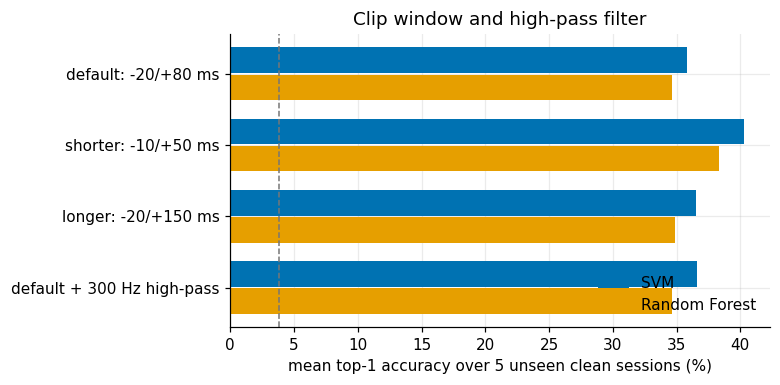

In [17]:
variants = [("default: -20/+80 ms", 0.02, 0.08, 0), ("shorter: -10/+50 ms", 0.01, 0.05, 0),
            ("longer: -20/+150 ms", 0.02, 0.15, 0), ("default + 300 Hz high-pass", 0.02, 0.08, 300)]
def _abl_one(pre, post, hp):
    df = build(CLEAN_DEV, pre, post, hp)
    s_acc, r_acc = [], []
    for held in CLEAN_DEV:
        r = run([s for s in CLEAN_DEV if s != held], held, df=df)
        s_acc.append(r["SVM"]["top1"]); r_acc.append(r["RF"]["top1"])
    return float(np.mean(s_acc)), float(np.mean(r_acc))
abl = []
for label, pre, post, hp in variants:
    sa, ra = cached(f"abl_{pre}_{post}_{hp}", lambda pre=pre, post=post, hp=hp: _abl_one(pre, post, hp))
    abl.append(dict(variant=label, SVM_top1=sa, RF_top1=ra))
abl = pd.DataFrame(abl)
display(abl.round(1))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
y = np.arange(len(abl))[::-1]
ax.barh(y + 0.19, abl.SVM_top1, 0.36, color=C_CLEAN, label="SVM")
ax.barh(y - 0.19, abl.RF_top1, 0.36, color=C_UNDER, label="Random Forest")
ax.set_yticks(y); ax.set_yticklabels(abl.variant)
ax.axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
ax.set_xlabel("mean top-1 accuracy over 5 unseen clean sessions (%)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Clip window and high-pass filter")
fig.tight_layout(); fig.savefig(FIG / "ablations.png"); plt.show()

**Reading the result.** Using a **shorter clip (10 ms before to 50 ms after the key-down)** gave the best result: SVM 40.3% against 35.8% for the default window (Random Forest 38.3% against 34.6%). A longer clip (36.6%) and a 300 Hz high-pass filter (36.6%) did not help. The only difference larger than the noise is the shorter window (about 4 to 5 points), which fits the idea that the click itself carries the information. These were compared on the same five sessions, so the gain is slightly optimistic; the final held-out test checks it.

## 11. Experiment 5: a neural network and data augmentation (development sessions)

Following what the research papers do (spectrogram input and a learned model), I compared the SVM with a small neural network on log-mel spectrograms, and tested two cheap improvements:
- **A shorter clip window** (10 ms before to 50 ms after the key-down instead of 20 ms before to 80 ms after), because Experiment 4 suggested the first part of the click carries most of the information.
- **Data augmentation:** for every *training* clip, three extra copies are made from the same recording: shifted 8 ms earlier, shifted 8 ms later, and with a little added noise (25 dB signal-to-noise). Test clips are never augmented, no external or synthetic audio is used, and only real training presses are copied.

Everything here is scored the same way as Experiment 1: leave one development session out (five runs). These sessions were used to *choose* the configuration, so the numbers are slightly optimistic; the honest number is the final test in the next section. The SVM uses C = 10 here (no tuning) and the neural net is averaged over 3 random seeds.

In [18]:
def press_sets(sessions, pre, post, aug, seed=0):
    # MFCC features and log-mel spectrograms for every press of the given sessions
    # (plus, if aug, three augmented copies of each press; the copies carry the index of the press they came from)
    rng = np.random.default_rng(seed)
    d = ALL[ALL.session.isin(sessions)].reset_index(drop=True)
    store = {}
    def seg(r, shift=0.0, noise_db=None):
        k = (r.session, r.key)
        if k not in store:
            a, sr = sf.read(RAW / r.session / f"{r.key}_burst.wav", dtype="float32")
            store[k] = (a[:, 0] if a.ndim == 2 else a, sr)
        a, sr = store[k]
        t0 = r.t_down + shift
        i0, i1 = int(round((t0 - pre) * sr)), int(round((t0 + post) * sr))
        if i0 < 0 or i1 > len(a):
            return None
        c = a[i0:i1].copy()
        if noise_db is not None:
            c = c + rng.normal(0, np.sqrt(np.mean(c ** 2)) * 10 ** (-noise_db / 20), len(c)).astype(np.float32)
        return c, sr
    def both(c, sr):
        f, _, _ = ef.clip_features(c, sr)
        pk = np.max(np.abs(c)); c = c / pk if pk > 0 else c
        m = librosa.feature.melspectrogram(y=c, sr=sr, n_fft=1024, hop_length=256, n_mels=40)
        return f, np.log(m + 1e-6).ravel()
    base = [both(*seg(r)) for r in d.itertuples()]
    out = dict(session=d.session.values, key=d.key.values,
               Xm=np.array([b[0] for b in base]), Xl=np.array([b[1] for b in base]))
    if aug:
        ai, am, al = [], [], []
        for i, r in enumerate(d.itertuples()):
            for kw in ({"shift": -0.008}, {"shift": 0.008}, {"noise_db": 25}):
                x = seg(r, **kw)
                if x is None:
                    continue
                f, l = both(*x); ai.append(i); am.append(f); al.append(l)
        out.update(ai=np.array(ai), am=np.array(am), al=np.array(al))
    return out

def svm10():
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED))

def mlp(seed):
    return make_pipeline(StandardScaler(), PCA(100, random_state=0),
                         MLPClassifier((128,), alpha=0.1, max_iter=400, random_state=seed))

def rank_eval(model, Xa, ya, Xb, yb):
    # fit, then return the rank of the true key in each test press's list of guesses (1 = first guess right)
    model.fit(Xa, ya)
    P = model.predict_proba(Xb); cls = model.classes_
    order = np.argsort(-P, axis=1)
    return np.array([list(cls[order[i]]).index(yb[i]) + 1 for i in range(len(yb))]), P, cls

def dev_eval(pre, post, aug):
    S = cached(f'S_dev_{pre}_{post}_{aug}', lambda: press_sets(CLEAN_DEV, pre, post, aug))
    rows = []
    for held in CLEAN_DEV:
        rows.append(cached(f'devfold_{pre}_{post}_{aug}_{held}', lambda held=held: _dev_fold(S, held, aug)))
    return pd.DataFrame(rows)

def _dev_fold(S, held, aug):
    if True:
        tr, te = S["session"] != held, S["session"] == held
        Xm, Xl, y = S["Xm"][tr], S["Xl"][tr], S["key"][tr]
        if aug:     # augmented copies of TRAINING presses only
            keep = S["session"][S["ai"]] != held
            Xm = np.vstack([Xm, S["am"][keep]]); Xl = np.vstack([Xl, S["al"][keep]])
            y = np.concatenate([y, S["key"][S["ai"][keep]]])
        rk, _, _ = rank_eval(svm10(), Xm, y, S["Xm"][te], S["key"][te])
        rm = [rank_eval(mlp(sd), Xl, y, S["Xl"][te], S["key"][te])[0] for sd in range(3)]
        return dict(held_out=held, SVM_top1=np.mean(rk <= 1) * 100, SVM_top5=np.mean(rk <= 5) * 100,
                    MLP_top1=np.mean([np.mean(r <= 1) for r in rm]) * 100, MLP_top5=np.mean([np.mean(r <= 5) for r in rm]) * 100)

DEV = {}
print("helpers ready")

helpers ready


In [19]:
DEV[("-20/+80 ms", "no")] = cached("dev_20_80_no", lambda: dev_eval(0.02, 0.08, False))
print("done")

done


In [20]:
DEV[("-20/+80 ms", "yes")] = cached("dev_20_80_yes", lambda: dev_eval(0.02, 0.08, True))
print("done")

done


In [21]:
DEV[("-10/+50 ms", "no")] = cached("dev_10_50_no", lambda: dev_eval(0.01, 0.05, False))
print("done")

done


In [22]:
DEV[("-10/+50 ms", "yes")] = cached("dev_10_50_yes", lambda: dev_eval(0.01, 0.05, True))
print("done")

done


,window,augmentation,SVM_top1,SVM_top5,MLP_top1,MLP_top5
0,-20/+80 ms,no,36.9,79.5,43.6,81.9
1,-20/+80 ms,yes,37.4,79.8,47.3,87.0
2,-10/+50 ms,no,41.2,79.7,52.9,87.2
3,-10/+50 ms,yes,42.3,80.8,56.8,90.6


per held-out session, top-1 (SVM / MLP), for each configuration:


-20/+80 ms, aug no          -20/+80 ms, aug yes           \
                     SVM_top1 MLP_top1            SVM_top1 MLP_top1   
held_out                                                              
session_06               31.5     46.9                31.5     44.6   
session_07               26.9     41.5                25.4     39.2   
session_11               40.8     45.1                40.0     49.0   
session_14               43.1     49.0                43.8     57.9   
session_15               42.3     35.6                46.2     45.9   

           -10/+50 ms, aug no          -10/+50 ms, aug yes           
                     SVM_top1 MLP_top1            SVM_top1 MLP_top1  
held_out                                                             
session_06               35.4     56.2                43.1     60.5  
session_07               31.5     56.4                36.9     52.3  
session_11               44.6     53.8                40.8     55.1  
session_14               47.7     53.1                45.4     59.7  
session_15               46.9     44.9                45.4     56.2

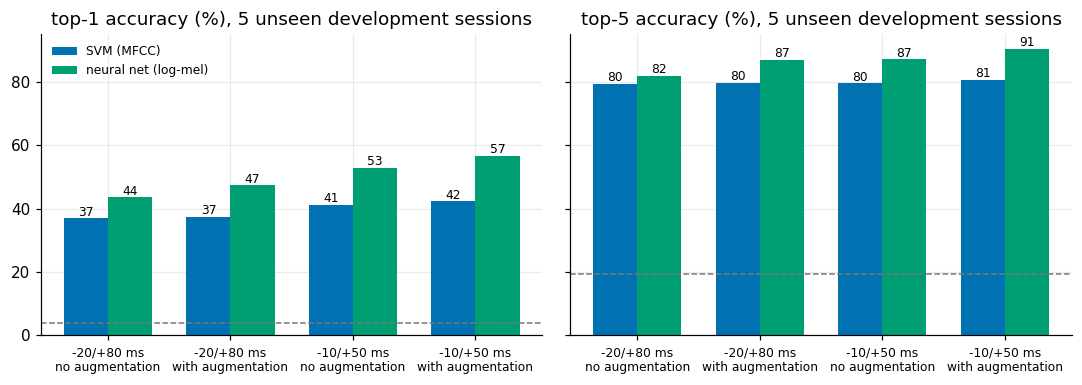

In [23]:
rows = [dict(window=w, augmentation=a, SVM_top1=df.SVM_top1.mean(), SVM_top5=df.SVM_top5.mean(),
             MLP_top1=df.MLP_top1.mean(), MLP_top5=df.MLP_top5.mean()) for (w, a), df in DEV.items()]
devtab = pd.DataFrame(rows)
display(devtab.round(1))
print("per held-out session, top-1 (SVM / MLP), for each configuration:")
display(pd.concat({f"{w}, aug {a}": df.set_index("held_out")[["SVM_top1", "MLP_top1"]] for (w, a), df in DEV.items()}, axis=1).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
labs = [f"{w}\n{'with' if a == 'yes' else 'no'} augmentation" for w, a in DEV]
x = np.arange(len(labs)); w_ = 0.36
for ax, key, title in zip(axes, ("top1", "top5"), ("top-1 accuracy", "top-5 accuracy")):
    b1 = ax.bar(x - w_ / 2, devtab[f"SVM_{key}"], w_, color=C_CLEAN, label="SVM (MFCC)")
    b2 = ax.bar(x + w_ / 2, devtab[f"MLP_{key}"], w_, color=C_OVER, label="neural net (log-mel)")
    for bars in (b1, b2):
        for rect in bars:
            ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.8, f"{rect.get_height():.0f}", ha="center", fontsize=8)
    ax.axhline(CHANCE1 if key == "top1" else CHANCE5, color=C_GREY, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(labs, fontsize=8); ax.set_title(title + " (%), 5 unseen development sessions")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "models_aug.png"); plt.show()

**Reading the result.** On the five development sessions (leave one out):
- The **shorter window** helps both models (SVM 36.9% to 41.2%, neural net 43.6% to 52.9%).
- **Augmentation** adds a little for the SVM (about 1 point) and more for the neural net (about 4 points).
- With both, the **neural net reaches 56.8% top-1 and 90.6% top-5**, against 42.3% and 80.8% for the SVM, and it beats the SVM on all five held-out sessions in that configuration.

These sessions were used to choose the setup, so the numbers are slightly optimistic. That is why the next section scores a session that was never used.

## 12. The final held-out test (session 16, used once)

**Rule:** session 16 was recorded and then left alone. No model, window, augmentation setting or `C` value was chosen with it. Both configurations below were fixed *before* it was scored:
- **original:** −20/+80 ms window, no augmentation (what Experiments 1 to 4 used);
- **final:** −10/+50 ms window with augmentation (the configuration that did best on the development sessions).

All models are trained on the five development sessions only (with augmentation, only copies of those training presses) and scored on the 130 presses of session 16.

In [24]:
def final_eval(pre, post, aug):
    S = cached(f'S_fin_{pre}_{post}_{aug}', lambda: press_sets(CLEAN_DEV + [FINAL_TEST], pre, post, aug))
    tr, te = np.isin(S["session"], CLEAN_DEV), S["session"] == FINAL_TEST
    Xm, Xl, y = S["Xm"][tr], S["Xl"][tr], S["key"][tr]
    if aug:     # augmented copies of TRAINING presses only
        keep = np.isin(S["session"][S["ai"]], CLEAN_DEV)
        Xm = np.vstack([Xm, S["am"][keep]]); Xl = np.vstack([Xl, S["al"][keep]])
        y = np.concatenate([y, S["key"][S["ai"][keep]]])
    yt = S["key"][te]
    out = dict(n_test=int(te.sum()), n_train=int(len(y)), y=yt)
    out["SVM"], _, cls = rank_eval(svm10(), Xm, y, S["Xm"][te], yt)
    out["RF"], _, _ = rank_eval(RandomForestClassifier(300, random_state=42, n_jobs=-1), Xm, y, S["Xm"][te], yt)
    mm = [cached(f'finmlp_{pre}_{post}_{aug}_{sd}', lambda sd=sd: rank_eval(mlp(sd), Xl, y, S["Xl"][te], yt)) for sd in range(5)]
    out["MLP_seeds"] = [m[0] for m in mm]
    out["MLP_P"] = np.mean([m[1] for m in mm], axis=0)       # average of the 5 seeds' probabilities (used in section 13)
    out["classes"] = cls
    return out

FIN = {}
FIN["original"] = cached("final_original", lambda: final_eval(0.02, 0.08, False))
print("original configuration scored")

original configuration scored


In [25]:
FIN["final"] = cached("final_final", lambda: final_eval(0.01, 0.05, True))
print("final configuration scored")

final configuration scored


original: neural net top-1 over the 5 seeds ranges from 50.0% to 53.8%
final: neural net top-1 over the 5 seeds ranges from 58.5% to 61.5%


,config,model,n_train,top1,pm,top3,top5
0,original,SVM,650,49.2,8.6,73.1,86.2
1,original,RF,650,49.2,8.6,76.2,83.8
2,original,neural net (mean of 5 seeds),650,52.2,8.6,78.9,86.9
3,final,SVM,2600,53.1,8.6,73.1,83.1
4,final,RF,2600,49.2,8.6,72.3,79.2
5,final,neural net (mean of 5 seeds),2600,60.2,8.4,81.5,90.6


test presses: 130   chance: top-1 3.8%  top-3 11.5%  top-5 19.2%


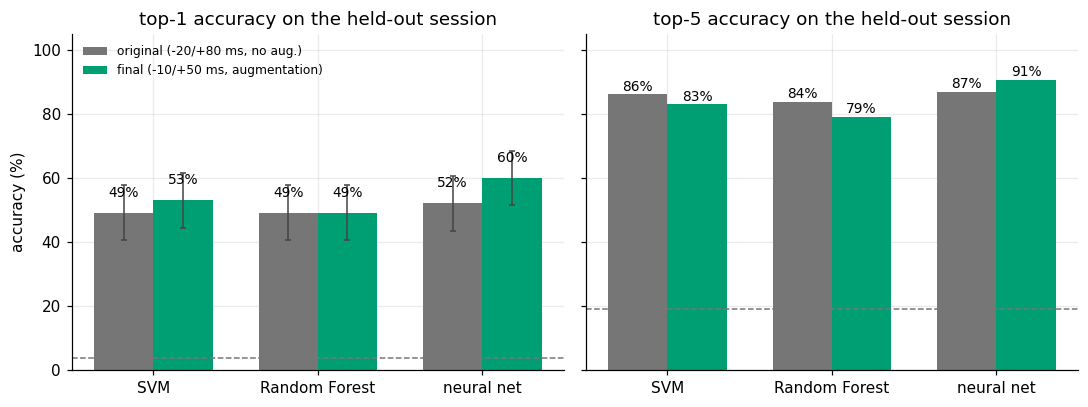

In [26]:
def topk_rank(rk, k): return float(np.mean(np.asarray(rk) <= k) * 100)
frows = []
for cname, R in FIN.items():
    for model in ("SVM", "RF"):
        frows.append(dict(config=cname, model=model, n_train=R["n_train"], top1=topk_rank(R[model], 1), pm=ci95(topk_rank(R[model], 1) / 100, R["n_test"]),
                          top3=topk_rank(R[model], 3), top5=topk_rank(R[model], 5)))
    m1 = [topk_rank(r, 1) for r in R["MLP_seeds"]]
    frows.append(dict(config=cname, model="neural net (mean of 5 seeds)", n_train=R["n_train"], top1=float(np.mean(m1)), pm=ci95(np.mean(m1) / 100, R["n_test"]),
                      top3=float(np.mean([topk_rank(r, 3) for r in R["MLP_seeds"]])), top5=float(np.mean([topk_rank(r, 5) for r in R["MLP_seeds"]]))))
    print(f"{cname}: neural net top-1 over the 5 seeds ranges from {min(m1):.1f}% to {max(m1):.1f}%")
final_tab = pd.DataFrame(frows)
display(final_tab.round(1))
print(f"test presses: {FIN['final']['n_test']}   chance: top-1 {CHANCE1:.1f}%  top-3 {CHANCE3:.1f}%  top-5 {CHANCE5:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
mods = ["SVM", "RF", "neural net (mean of 5 seeds)"]; names = ["SVM", "Random Forest", "neural net"]
x = np.arange(3); w_ = 0.36
for ax, key, title in zip(axes, ("top1", "top5"), ("top-1", "top-5")):
    for j, (cname, col, lab) in enumerate((("original", C_GREY, "original (-20/+80 ms, no aug.)"), ("final", C_OVER, "final (-10/+50 ms, augmentation)"))):
        d = final_tab[final_tab.config == cname].set_index("model").loc[mods]
        b = ax.bar(x + (j - 0.5) * w_, d[key], w_, color=col, label=lab,
                   yerr=d.pm if key == "top1" else None, error_kw=dict(lw=1, capsize=2, ecolor="#444"))
        for rect, v in zip(b, d[key]):
            ax.text(rect.get_x() + rect.get_width() / 2, v + (5 if key == "top1" else 1.2), f"{v:.0f}%", ha="center", fontsize=9)
    ax.axhline(CHANCE1 if key == "top1" else CHANCE5, color=C_GREY, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(names); ax.set_title(f"{title} accuracy on the held-out session")
    ax.set_ylim(0, 105)
axes[0].legend(frameon=False, fontsize=8, loc="upper left"); axes[0].set_ylabel("accuracy (%)")
fig.tight_layout(); fig.savefig(FIG / "final_test.png"); plt.show()

**Reading the result.** On the held-out session 16 (130 presses, about ±8.6 points at 95%), trained only on the five development sessions:
- **Original setup** (−20/+80 ms, no augmentation): SVM 49%, Random Forest 49%, neural net 52% top-1.
- **Final setup** (−10/+50 ms, augmentation): SVM 53%, Random Forest 49%, **neural net 60.2% top-1 and 90.6% top-5** (the five random seeds range from 58.5% to 61.5%). Chance is 3.8% and 19.2%.

The neural net is the best model, and the result agrees with the development sessions (56.8% there, 60.2% here), so the choice was not just luck on those sessions. But the intervals of the SVM and the neural net overlap on one session, so the honest statement is: *the neural net looks better and was better on all five development sessions, but one test session cannot prove it.* Published attacks reach about 95% with a phone placed next to the laptop and much more data; this is a laptop microphone and a small dataset.

## 13. How much does this help a password attacker?

A top-5 accuracy of about 90% does not recover a password directly, but it can shrink the search a lot. This section measures how much, using the final model's real probabilities on the held-out session.

**Method.** Simulate random lowercase passwords of 6 and of 8 letters. For each letter pick a random held-out press of that key and take the model's probability for all 26 letters. An attacker who enumerates candidate passwords from the most to the least likely (multiplying the per-key probabilities) needs a certain number of guesses before hitting the true password; that number is counted exactly. This is compared with guessing blindly (a budget of B guesses succeeds with probability B / 26^length).

**What this assumes (so it is an optimistic estimate for the attacker):** isolated key presses at known times, the same keyboard and typist as the training data, uniformly random lowercase passwords, and independent keystrokes.

,length,guesses,attack_success_pct,blind_guessing_pct
0,6,100,50.667,0.000
1,6,"1,000",81.333,0.000
2,6,"10,000",94.667,0.003
3,6,"100,000",99.667,0.032
4,6,"1,000,000",100.000,0.324
5,6,"10,000,000",100.000,3.237
6,8,100,29.000,0.000
7,8,"1,000",51.333,0.000
8,8,"10,000",73.000,0.000
9,8,"100,000",89.333,0.000


6-letter passwords: median guesses needed 98 (blind guessing: median about 154,457,888); search space 308,915,776
8-letter passwords: median guesses needed 824 (blind guessing: median about 104,413,532,288); search space 208,827,064,576


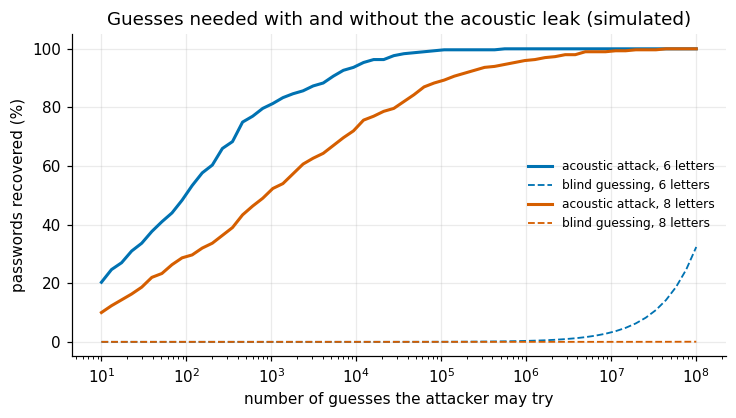

In [27]:
def pw_rank(P, true_idx):
    # number of 'candidate passwords' at least as likely as the true one (counted exactly with a meet-in-the-middle sort)
    L = np.log(P + 1e-9); N = len(L); h = N // 2
    def sums(Ls):
        s = np.zeros(1)
        for l in Ls:
            s = (s[:, None] + l[None, :]).ravel()
        return s
    A = sums(L[:h]); B = np.sort(sums(L[h:]))
    T = L[np.arange(N), true_idx].sum()
    return int((len(B) - np.searchsorted(B, T - A, side="right")).sum()) + 1

def simulate_pw(P, y, classes, N, trials, seed=0):
    rng = np.random.default_rng(seed)
    cls = list(classes)
    rows_of = {k: np.where(y == k)[0] for k in cls}
    ranks = []
    for _ in range(trials):
        letters = rng.integers(0, 26, N)
        rows = [rng.choice(rows_of[cls[i]]) for i in letters]
        ranks.append(pw_rank(P[rows], letters))
    return np.array(ranks)

FR = FIN["final"]
PW = {N: cached(f"pw_{N}", lambda N=N: simulate_pw(FR["MLP_P"], FR["y"], FR["classes"], N, 300)) for N in (6, 8)}
budgets = [10 ** k for k in range(2, 8)]
prow = []
for N, rk in PW.items():
    for b in budgets:
        prow.append(dict(length=N, guesses=f"{b:,}", attack_success_pct=float(np.mean(rk <= b) * 100), blind_guessing_pct=min(100.0, b / 26 ** N * 100)))
pwtab = pd.DataFrame(prow)
display(pwtab.round(3))
for N, rk in PW.items():
    print(f"{N}-letter passwords: median guesses needed {int(np.median(rk)):,} (blind guessing: median about {26 ** N // 2:,}); search space {26 ** N:,}")

fig, ax = plt.subplots(figsize=(6.8, 3.9))
xs = np.logspace(1, 8, 60)
for N, col in ((6, C_CLEAN), (8, C_NOISE)):
    ax.plot(xs, [np.mean(PW[N] <= b) * 100 for b in xs], color=col, lw=2, label=f"acoustic attack, {N} letters")
    ax.plot(xs, np.minimum(100, xs / 26 ** N * 100), color=col, lw=1.2, ls="--", label=f"blind guessing, {N} letters")
ax.set_xscale("log"); ax.set_xlabel("number of guesses the attacker may try"); ax.set_ylabel("passwords recovered (%)")
ax.set_title("Guesses needed with and without the acoustic leak (simulated)")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "password_search.png"); plt.show()

**Reading the result.** Using the model's real probabilities on the held-out session, in this idealised setting an attacker who tries the most likely passwords first needs a **median of about 100 guesses for a 6-letter password and about 800 for an 8-letter one** (blind guessing: about 150 million and 100 billion). Within 1,000 guesses it recovers about 81% of the 6-letter and 51% of the 8-letter passwords, and within 100,000 guesses about 99.7% and 89%, where blind guessing would succeed in well under 0.1% of cases.

**Be careful what this shows.** It is an *upper bound* on the threat: isolated presses at known times, the same keyboard and typist as the training data, uniformly random lowercase passwords, and a quiet room. Real typing (overlapping keys, shift, backspace, background noise) would be much harder, and the white-noise defence took this attack close to chance. The point is that even a 60%-accurate key guesser shrinks the search space enormously.

## 14. Real-time style test (replay of the live demo)

The live demo (`demo/live_guess.py`) asks me to press a random key three times, finds the clicks **from the audio alone** (no key log), and shows the model's top 3 guesses with a confidence. The three presses are combined by multiplying their probabilities, since they are the same key.

Here the same code is run on the recorded bursts of a clean session the model never heard (trained on the five development sessions, replayed on session 16), one burst per letter. This tests two things at once: the click finder and the three-press combination.

In [28]:
spec = importlib.util.spec_from_file_location("live_guess", ROOT / "demo" / "live_guess.py")
lg = importlib.util.module_from_spec(spec); spec.loader.exec_module(lg)

tr = ALL[ALL.session.isin(TRAIN_BASE)]
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale", C=10, probability=True, random_state=SEED)).fit(tr[FEAT].values, tr.key.values)
payload = dict(model=model, classes=list(model.classes_), pre=PRE, post=POST, highpass=0.0)

rows = []
for key in ef.KEYS:
    a, sr = sf.read(RAW / BASELINE_TEST / f"{key}_burst.wav", dtype="float32")
    a = a[:, 0] if a.ndim == 2 else a
    g = lg.guess(payload, a, sr)
    if not g["ok"]:
        rows.append(dict(target=key, detected=False)); continue
    t3 = g["top3"]
    rows.append(dict(target=key, detected=True, top1=t3[0][0], conf1=t3[0][1], top2=t3[1][0], top3=t3[2][0],
                     hit1=t3[0][0] == key, hit3=key in [k for k, _ in t3],
                     single_press_hits=sum(p == key for p in g["per_press_top1"])))
rep = pd.DataFrame(rows)
det = rep[rep.detected]
print(f"letters replayed: {len(rep)}   with 3 clear clicks found from audio alone: {len(det)}")
print(f"combined 3 presses: top-1 {det.hit1.mean() * 100:.0f}% ({int(det.hit1.sum())}/{len(det)})   "
      f"top-3 {det.hit3.mean() * 100:.0f}% ({int(det.hit3.sum())}/{len(det)})   (chance 4% / 12%)")
print(f"single presses    : top-1 {det.single_press_hits.sum() / (3 * len(det)) * 100:.0f}% of {3 * len(det)} individual clicks")
print(f"uncertainty with only {len(det)} letters: roughly +/- {ci95(det.hit1.mean(), len(det)):.0f} points on top-1")
display(det[["target", "top1", "conf1", "top2", "top3", "hit1", "hit3"]].round(2).head(10))

letters replayed: 26   with 3 clear clicks found from audio alone: 26
combined 3 presses: top-1 65% (17/26)   top-3 88% (23/26)   (chance 4% / 12%)
single presses    : top-1 45% of 78 individual clicks
uncertainty with only 26 letters: roughly +/- 18 points on top-1


,target,top1,conf1,top2,top3,hit1,hit3
0,A,A,0.94,N,Q,True,True
1,B,B,0.54,M,Q,True,True
2,C,C,0.99,X,Z,True,True
3,D,D,0.73,S,X,True,True
4,E,E,0.28,W,D,True,True
5,F,F,0.99,D,C,True,True
6,G,Y,0.62,G,H,False,True
7,H,U,0.43,H,J,False,True
8,I,J,0.68,I,H,False,True
9,J,U,0.49,Y,J,False,True


**Reading the result.** On the 26 recorded letters of session 16, the click finder found three clear clicks from the audio alone every time. Combining the three presses gave **65% top-1 (17 of 26) and 88% top-3 (23 of 26)**, while single presses alone were right 45% of the time. With only 26 letters the uncertainty is large (about ±18 points), so this mainly shows that the live-demo path (click finder plus three-press combination) works and that pressing the same key three times helps.

## 15. Limitations and honest conclusions

**Limitations**
- **One laptop, one typist, one room.** The results describe this keyboard and this typing style, not keyboards in general.
- **Small data.** A session has 5 presses per key, so each test session has about 130 presses and a top-1 result carries about ±7 to ±9 points of uncertainty. Several of the differences discussed above (for example SVM against neural net on one session) are inside that uncertainty.
- **Segmentation uses logged key times** in the main experiments. A real attacker would have to find the clicks from audio; the replay test shows a simple click finder works for isolated presses, but continuous typing with overlapping keys was not tested.
- **Isolated bursts, not real typing.** Each recording is five presses of one key, about one second apart, not a sentence typed at speed.
- **Sessions of the same defence are not identical.** For example the two cloth sessions differ in how loud the keys were, and the two noise sessions differ a little in their high-frequency content. This makes the adaptive test somewhat harder than it would be with a perfectly repeated setup.
- **Different recording times.** Background rumble changed between sessions (a low-frequency component only), which can move the clean baseline.
- **Choices were made on the development sessions.** The window, augmentation and model were chosen on sessions 06 to 15 and then scored once on session 16. One held-out session is a single test, not a guarantee for other days, rooms or typists.

**What I would do next:** typing of real words (continuous typing), a language model to correct single-key guesses, a larger spectrogram model such as a CNN, other typists and keyboards, and stronger defences against the strongest adaptive attacker.

**Conclusions**
1. **The attack works on this keyboard.** On a session it had never heard, the best model gets the key right on the first guess about **60% of the time (top-5: 91%)**, against 3.8% (19%) for guessing. The SVM gets 53%.
2. **How you test matters.** A random split inflated accuracy (52% against 36% for the SVM in leave-one-session-out), so the honest session-separated numbers are the ones to trust.
3. **More training sessions help most**, then a shorter clip window (the click itself carries the information) and light augmentation of real training clips. A 300 Hz high-pass filter did not help.
4. **White noise is the strongest defence:** it brings an attacker trained on clean typing to chance. An adaptive attacker with several noisy sessions wins part of it back (about 14% to 17% top-1), still far below undefended typing.
5. **Cloth over the keys helps but does not stop it:** about 47% falls to about 27% to 31%, and retraining does not restore the undefended level. Cloth under the stand has only a modest, uncertain effect.
6. **Threat:** in an idealised setting a 60%-accurate key guesser shrinks an 8-letter password search from 10^11 to a few hundred or thousand guesses, but real typing was not tested.
7. **Limits:** one keyboard, one typist, one laptop microphone, isolated presses, and a single held-out test session.

## 16. How to re-run with more sessions

1. Record a new session with `python src/recording.py` (the key logger is part of it).
2. Add the session name to `CLEAN_DEV` (clean sessions) or to `DEFENDED` / `DEFENCES` in the configuration cell near the top of this notebook.
3. Run all cells again. Everything is recomputed from the raw audio; the figures are saved to `final_notebook/figures/`.

Keep one clean session (`FINAL_TEST`) **out** of every choice and look at it only once at the end: that is the honest final number. Set the environment variable `KEYLEAK_CACHE` to a folder to cache the slow cells while you work.

*The numbers quoted in the written commentary belong to the run that produced this notebook. After adding sessions, re-read the commentary against the new tables.*